In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
import sys, os

sys.path.append("/home/548/cd3022/repos/nowcast-evaluation/src")
import metric_aggregation as ma

In [2]:
DIT_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/per-forecast/CPDiT")
OF_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/per-forecast/GSO_OF")
SP_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/per-forecast/SmartPersistence")

In [3]:
# 1. Load per-forecast metrics (dims: time = issue time, lead_time)
metrics = {"DiT": ma.load_metrics(DIT_PATH), "GSO-OF": ma.load_metrics(OF_PATH),
           "Smart persistence": ma.load_metrics(SP_PATH)}
# 2. Score both models on exactly the same forecasts
metrics = ma.common_sample(metrics)
# 3. Pooled FSS per lead time: 1 - Σdiff / (Σfcst + Σobs)
scores = {m: ma.aggregate(ds) for m, ds in metrics.items()}

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.11/lib/python3.11/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'kerchunk' loading failed:
No module named 'zarr.core.array_spec'; 'zarr.core' is not a package
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [4]:
# 4. Uncertainty: bootstrap whole days (forecasts within a day are correlated).
#    Both models use the same resampled days, so their difference is paired.
def daily_fss_sums(ds, window):
    """Per-day sums of the FSS components, shape (component, day, lead_time)."""
    ds = ds.where(ds["valid"] == 1)
    comps = [ds[f"fss_{window}_{c}"].resample(time="1D").sum().fillna(0)
             for c in ("fcst", "obs", "diff")]
    return np.stack([c.transpose("time", "lead_time").values for c in comps])

def bootstrap_fss(metrics, window, n_boot=2000, seed=0):
    sums = {m: daily_fss_sums(ds, window) for m, ds in metrics.items()}
    n_days = next(iter(sums.values())).shape[1]
    idx = np.random.default_rng(seed).integers(0, n_days, size=(n_boot, n_days))
    return {m: 1 - d[idx].sum(1) / (f[idx].sum(1) + o[idx].sum(1))
            for m, (f, o, d) in sums.items()}

def bootstrap_mean(metrics, var, n_boot=2000, seed=0):
    """Bootstrap the mean of a per-forecast metric over valid forecasts, resampling days.

    Uses the same seed (so the same resampled days) as `bootstrap_fss`.
    """
    out = {}
    for m, ds in metrics.items():
        da = ds[var].where(ds["valid"] == 1)
        total = da.resample(time="1D").sum().fillna(0).transpose("time", "lead_time").values
        count = da.notnull().resample(time="1D").sum().fillna(0).transpose("time", "lead_time").values
        idx = np.random.default_rng(seed).integers(0, total.shape[0], size=(n_boot, total.shape[0]))
        out[m] = total[idx].sum(1) / count[idx].sum(1)
    return out

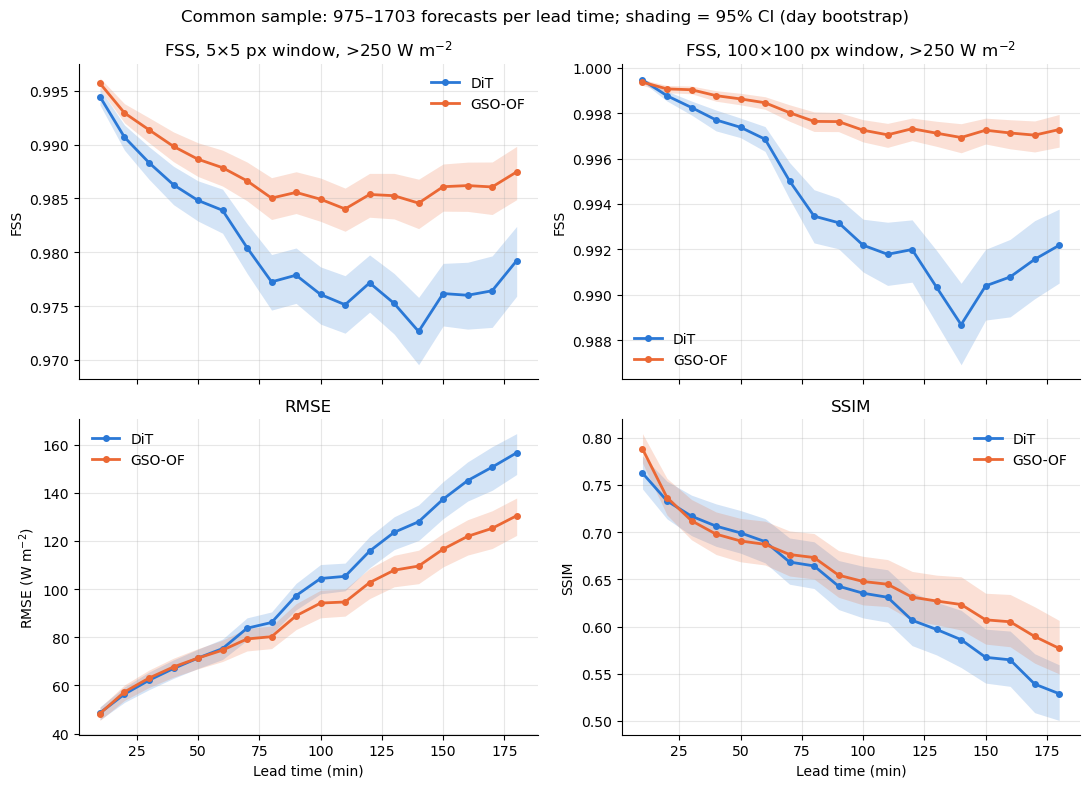

In [6]:
lead = scores["DiT"]["lead_time"].values
colors = {"DiT": "#2a78d6", "GSO-OF": "#eb6834", "Smart persistence": "#7a7a7a"}

# (variable in `scores`, title, y-label, bootstrap samples)
panels = [
    ("fss_small", "FSS, 5×5 px window, >250 W m$^{-2}$", "FSS", bootstrap_fss(metrics, "small")),
    ("fss_large", "FSS, 100×100 px window, >250 W m$^{-2}$", "FSS", bootstrap_fss(metrics, "large")),
    ("rmse", "RMSE", "RMSE (W m$^{-2}$)",
     {m: np.sqrt(b) for m, b in bootstrap_mean(
         {k: ds.assign(mse=ds["rmse"] ** 2) for k, ds in metrics.items()}, "mse").items()}),
    ("ssim", "SSIM", "SSIM", bootstrap_mean(metrics, "ssim")),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, (var, title, ylabel, boot) in zip(axes.flat, panels):
    for m in metrics:
        lo, hi = np.percentile(boot[m], [2.5, 97.5], axis=0)
        ax.fill_between(lead, lo, hi, color=colors[m], alpha=0.2, linewidth=0)
        ax.plot(lead, scores[m][var], color=colors[m], lw=2, marker="o", ms=4, label=m)
    ax.set(title=title, ylabel=ylabel)
    ax.legend(frameon=False)
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("Lead time (min)")
n = scores["DiT"]["n"].values
fig.suptitle(f"Common sample: {n.min()}–{n.max()} forecasts per lead time; shading = 95% CI (day bootstrap)")
fig.tight_layout()